# Pharmacy Medicine Demand & Expiry-Risk Forecasting
### Advanced Machine Learning Internship Project | Algions AI Labs Private Limited

This project develops an end-to-end decision-support machine learning solution for pharmacy supply chain management. The dual objectives of the project are:
1. Product-level monthly demand forecasting to optimize inventory replenishment and prevent stockouts.
2. Medicine inventory turnover and batch expiry-risk identification following the First Expiry, First Out (FEFO) principle.

## 1. Project Introduction
In healthcare systems and pharmacy operations, managing pharmaceutical inventory presents a dual challenge. On one hand, stockouts of essential medicines endanger patient lives and disrupt clinical care. On the other hand, overstocking leads to financial loss and drug expiration on pharmacy shelves.

This project uses real historical logistics records from health facilities (DHIS2) and central inventory records to build reproducible demand forecasts, assess inventory turnover risks, and generate operational decision-support recommendations.

## 2. Problem Statement
Public health facilities frequently experience severe imbalances in medicine stock. In many clinics, essential antibiotics and maternal health supplies face sudden stockouts, while in others, medicines sit unused until their shelf-life expires. 

Traditional inventory management relies on static reorder points or simple historical consumption averages that fail to adapt to seasonality, lead-time delays, and localized demand shifts. The goal is to build machine learning models that forecast demand accurately and highlight inventory units at risk of stockout or expiration.

## 3. Project Objectives
The primary objectives of this study are:
- Perform data profiling, cleaning, and exploratory data analysis on real health facility logistics records and central warehouse inventory.
- Engineer time-series features without lookahead bias, including lag features and rolling window statistics.
- Implement and compare a baseline model against machine learning regressors (Random Forest and Gradient Boosting) using MAE, RMSE, and WAPE.
- Analyze facility and national inventory turnover, calculate Months of Stock (MOS), and model batch-level expiry risks under the FEFO principle.
- Export trained model artifacts and build an interactive Streamlit application for decision-makers.

## 4. Business Understanding
To ensure the machine learning models translate into practical pharmacy operations, we specify the operational parameters:
- **Prediction Unit:** Individual medicine product per monthly logistics reporting cycle.
- **Prediction Target:** Next month's total demand (consumption quantity at t+1).
- **Forecasting Horizon:** 1 month ahead (matching the routine public health procurement cycle).
- **Decision Point:** The end of each calendar month, when facility stock managers review closing balances and prepare stock requisitions.
- **Stock Rotation Policy:** First Expiry, First Out (FEFO), prioritizing the dispensing of batches with earlier expiration dates.

## 5. Importing Required Libraries
We load the necessary scientific computing, data manipulation, machine learning, and visualization libraries.

In [1]:
import os
import tempfile
os.environ['MPLCONFIGDIR'] = tempfile.mkdtemp()
import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 6. Loading the Real Datasets
We load the real historical consumption dataset (S2_Dhis2Data.csv) and the central inventory dataset (S3.csv). The paths adapt automatically whether the notebook is executed from the repository root or the data folder.

In [2]:
consumption_file_path = 'data/S2_Dhis2Data.csv' if os.path.exists('data/S2_Dhis2Data.csv') else ('../data/S2_Dhis2Data.csv' if os.path.exists('../data/S2_Dhis2Data.csv') else 'S2.csv/S2_Dhis2Data.csv')
inventory_file_path = 'data/S3.csv' if os.path.exists('data/S3.csv') else ('../data/S3.csv' if os.path.exists('../data/S3.csv') else 'S3.csv')

consumption_data = pd.read_csv(consumption_file_path)
inventory_data = pd.read_csv(inventory_file_path)

print('Consumption Data Shape:', consumption_data.shape)
print('Inventory Data Shape:', inventory_data.shape)

Consumption Data Shape: (457225, 16)
Inventory Data Shape: (341, 3)


In [3]:
consumption_data.head()

,hf_pk,name1,date,stockout,received,consumption,closeBalance,openBalance,facility_type,lat,long,district,quarter,productID,normAvg,normStd
0,663,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",10/1/19,0,0,59,0,59,MCHP,9.089409,-12.00467,Bombali,2019Q4,1,152.030426,228.309369
1,667,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",10/1/19,0,0,70,0,70,CHP,8.903324,-12.04545,Bombali,2019Q4,1,152.030426,228.309369
2,745,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",10/1/19,1,0,14,0,14,CHP,8.807020,-12.08181,Bombali,2019Q4,1,152.030426,228.309369
3,753,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",10/1/19,0,0,100,0,100,CHP,8.791610,-12.06068,Bombali,2019Q4,1,152.030426,228.309369
4,725,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",10/1/19,0,0,100,0,100,MCHP,9.032880,-12.04858,Bombali,2019Q4,1,152.030426,228.309369


In [4]:
inventory_data.head()

,Item,Stock,Quarter
0,"(Syringe, AutoDestruct, SoloShot)",0,2023Q1
1,"(Syringe, AutoDestruct, SoloShot)",219034,2022Q4
2,"Acetazolamide 250mg, Tab",14059,2023Q2
3,"Albendazole 400mg, Tab",2767594,2023Q1
4,"Albendazole 400mg, Tab",1860527,2023Q2


## 7. Understanding the Datasets
We examine data dimensions, column types, unique facility counts, and product identifiers across both datasets.

In [5]:
print('Consumption Data Columns and Types:')
print(consumption_data.dtypes)
print('')
print('Inventory Data Columns and Types:')
print(inventory_data.dtypes)

Consumption Data Columns and Types:
hf_pk              int64
name1             object
date              object
stockout           int64
received           int64
consumption        int64
closeBalance       int64
openBalance        int64
facility_type     object
lat              float64
long             float64
district          object
quarter           object
productID          int64
normAvg          float64
normStd          float64
dtype: object

Inventory Data Columns and Types:
Item       object
Stock       int64
Quarter    object
dtype: object


In [6]:
print('Unique Facilities:', consumption_data['hf_pk'].nunique())
print('Unique Medicines in Consumption Data:', consumption_data['productID'].nunique())
print('Unique Reporting Dates:', consumption_data['date'].nunique())
print('Unique Items in Central Inventory:', inventory_data['Item'].nunique())
print('Quarters in Central Inventory:', inventory_data['Quarter'].unique())

Unique Facilities: 1091
Unique Medicines in Consumption Data: 36
Unique Reporting Dates: 50
Unique Items in Central Inventory: 150
Quarters in Central Inventory: ['2023Q1' '2022Q4' '2023Q2' '2023Q3']


## 8. Data Structure and Column Description
The consumption dataset represents routine monthly DHIS2 reporting from public health facilities:
- **hf_pk:** Health facility primary identifier.
- **name1:** Generic medicine name and dosage form.
- **date:** Monthly reporting timestamp (first day of each month).
- **stockout:** Binary indicator (1 if facility stocked out during the month, 0 otherwise).
- **received:** Quantity of medicine received during the reporting period.
- **consumption:** Quantity of medicine dispensed to patients during the month.
- **closeBalance:** Inventory balance remaining at the end of the month.
- **openBalance:** Inventory balance available at the beginning of the month.
- **facility_type:** Healthcare tier (MCHP, CHP, CHC, Hospital).
- **district:** Geographic health administration district.
- **quarter:** Calendar quarter identifier.
- **productID:** Unique numerical product identifier.

The central inventory dataset (S3.csv) tracks national warehouse stock levels by item and quarter. We formally verify whether batch identifiers or manufacturer expiration dates are present in either dataset.

In [7]:
consumption_has_batch = 'batch_id' in [col.lower() for col in consumption_data.columns]
consumption_has_expiry = 'expiry_date' in [col.lower() for col in consumption_data.columns]
inventory_has_batch = 'batch_id' in [col.lower() for col in inventory_data.columns]
inventory_has_expiry = 'expiry_date' in [col.lower() for col in inventory_data.columns]

dataset_audit_table = pd.DataFrame({
    'Dataset': ['S2_Dhis2Data (Consumption)', 'S3 (Inventory)'],
    'Has_Batch_ID': [consumption_has_batch, inventory_has_batch],
    'Has_Expiry_Date': [consumption_has_expiry, inventory_has_expiry],
    'Primary_Identifier': ['productID / name1', 'Item'],
    'Time_Resolution': ['Monthly (50 points)', 'Quarterly (4 points)']
})
dataset_audit_table

,Dataset,Has_Batch_ID,Has_Expiry_Date,Primary_Identifier,Time_Resolution
0,S2_Dhis2Data (Consumption),False,False,productID / name1,Monthly (50 points)
1,S3 (Inventory),False,False,Item,Quarterly (4 points)


## 9. Data Quality Analysis
We check for numerical anomalies such as negative consumption, invalid stock balances, or malformed stockout indicators.

In [8]:
consumption_data[['consumption', 'received', 'openBalance', 'closeBalance', 'stockout']].describe()

,consumption,received,openBalance,closeBalance,stockout
count,457225.000000,457225.000000,457225.000000,457225.000000,457225.000000
mean,161.034016,162.022020,489.334450,492.713695,0.135504
std,378.274544,663.502838,1840.770745,1873.561150,0.342262
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.000000,0.000000,10.000000,10.000000,0.000000
50%,50.000000,0.000000,100.000000,100.000000,0.000000
75%,173.000000,50.000000,480.000000,480.000000,0.000000
max,48000.000000,100000.000000,282000.000000,281880.000000,1.000000


In [9]:
negative_consumption_count = (consumption_data['consumption'] < 0).sum()
negative_received_count = (consumption_data['received'] < 0).sum()
negative_balance_count = (consumption_data['closeBalance'] < 0).sum()
invalid_stockout_count = (~consumption_data['stockout'].isin([0, 1])).sum()

print('Negative Consumption Count:', negative_consumption_count)
print('Negative Received Count:', negative_received_count)
print('Negative Closing Balance Count:', negative_balance_count)
print('Invalid Stockout Values Count:', invalid_stockout_count)

Negative Consumption Count: 0
Negative Received Count: 0
Negative Closing Balance Count: 0
Invalid Stockout Values Count: 0


## 10. Missing Value Analysis
We inspect both datasets for missing or null values across all fields.

In [10]:
print('Missing values in Consumption Data:')
print(consumption_data.isnull().sum())
print('')
print('Missing values in Inventory Data:')
print(inventory_data.isnull().sum())

Missing values in Consumption Data:
hf_pk            0
name1            0
date             0
stockout         0
received         0
consumption      0
closeBalance     0
openBalance      0
facility_type    0
lat              0
long             0
district         0
quarter          0
productID        0
normAvg          0
normStd          0
dtype: int64

Missing values in Inventory Data:
Item       0
Stock      0
Quarter    0
dtype: int64


## 11. Duplicate Detection
We identify and quantify any duplicate rows in both datasets.

In [11]:
consumption_duplicates = consumption_data.duplicated().sum()
inventory_duplicates = inventory_data.duplicated().sum()

print('Consumption Duplicates Count:', consumption_duplicates)
print('Inventory Duplicates Count:', inventory_duplicates)

Consumption Duplicates Count: 0
Inventory Duplicates Count: 1


In [12]:
inventory_data[inventory_data.duplicated(keep=False)]

,Item,Stock,Quarter
196,Levoplant - Levonorgestrel two rod 150mg implant,55532,2023Q2
197,Levoplant - Levonorgestrel two rod 150mg implant,55532,2023Q2


## 12. Data Cleaning
We parse the date column into proper datetime timestamps, eliminate duplicate records from the inventory dataset, and ensure records are chronologically organized.

In [13]:
consumption_data['date'] = pd.to_datetime(consumption_data['date'], format='%m/%d/%y')
inventory_data = inventory_data.drop_duplicates().reset_index(drop=True)
consumption_data = consumption_data.sort_values(['productID', 'date']).reset_index(drop=True)

print('Cleaned Consumption Records:', len(consumption_data))
print('Cleaned Inventory Records:', len(inventory_data))
print('Date Range:', consumption_data['date'].min().strftime('%Y-%m-%d'), 'to', consumption_data['date'].max().strftime('%Y-%m-%d'))

Cleaned Consumption Records: 457225
Cleaned Inventory Records: 340
Date Range: 2019-10-01 to 2023-11-01


## 13. Exploratory Data Analysis
We analyze demand patterns across medicines, facility types, and administrative districts, and evaluate overall stockout rates.

In [14]:
medicine_consumption_totals = consumption_data.groupby(['productID', 'name1'])['consumption'].agg(['sum', 'mean', 'max']).reset_index()
medicine_consumption_totals.columns = ['productID', 'Medicine_Name', 'Total_Consumption', 'Monthly_Avg_Per_Facility', 'Peak_Single_Month']
medicine_consumption_totals = medicine_consumption_totals.sort_values('Total_Consumption', ascending=False).reset_index(drop=True)
medicine_consumption_totals.head(10)

,productID,Medicine_Name,Total_Consumption,Monthly_Avg_Per_Facility,Peak_Single_Month
0,34,"Folic Acid 5mg, Tab",15774051,510.354957,48000
1,50,"Paracetamol (Acetaminophen) 500mg, Tab",13436208,575.377184,28670
2,46,"Paracetamol (Acetaminophen) 250mg, Dispersible...",12829118,461.313125,20000
3,43,"Zinc Sulphate 20mg, Dispersible, Tab",8288536,218.544956,39854
4,38,"Albendazole 400mg, Tab",4761658,124.134049,11905
5,39,"Oral Rehydration Salts (ORS), Sachet",4517921,122.973434,9000
6,44,"Glove, Exam, Latex, Medium, Nonsterile, Dispos...",3402674,182.792049,25500
7,42,"Methyldopa 250mg, Tab",2502174,72.830772,11313
8,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",1381802,149.545671,5460
9,32,"Ampicillin 500mg, Pdr for IM/IV, Inj, Vial",1372730,65.809962,8760


In [15]:
facility_summary = consumption_data.groupby('facility_type').agg(
    facility_count=('hf_pk', 'nunique'),
    total_consumption=('consumption', 'sum'),
    stockout_rate=('stockout', 'mean')
).reset_index()
facility_summary

,facility_type,facility_count,total_consumption,stockout_rate
0,CHC,215,20764470,0.131084
1,CHP,333,21168725,0.142687
2,Hospital,5,2058565,0.030243
3,MCHP,538,29637018,0.133949


In [16]:
overall_stockout_percentage = consumption_data['stockout'].mean() * 100
print('Overall Health Facility Stockout Rate:', round(overall_stockout_percentage, 2), '%')

Overall Health Facility Stockout Rate: 13.55 %


## 14. Data Visualization
We visualize consumption trends over time, top medicines by volume, and stockout vulnerability across facility types.

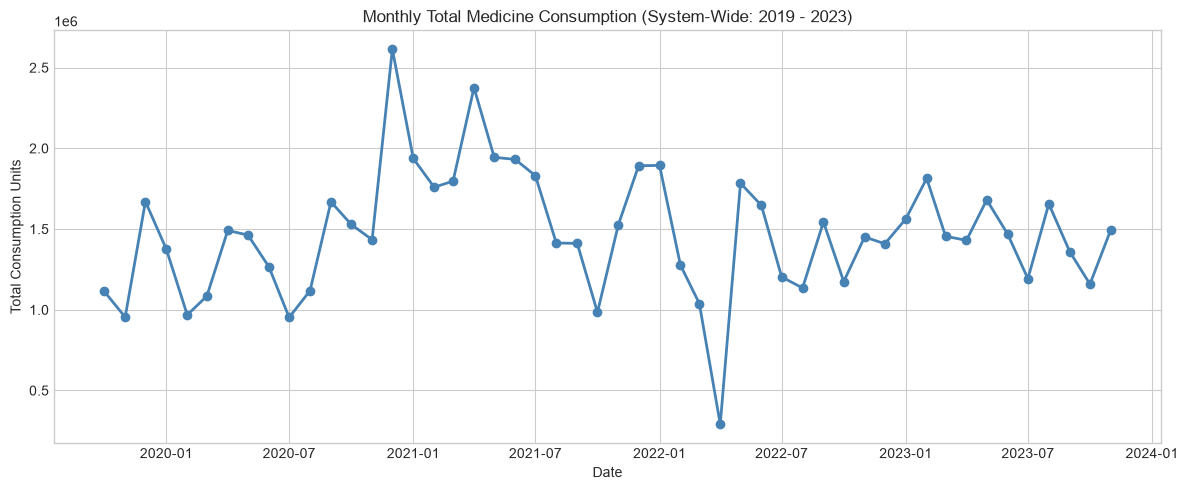

In [17]:
monthly_system_demand = consumption_data.groupby('date')['consumption'].sum().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_system_demand['date'], monthly_system_demand['consumption'], color='steelblue', linewidth=2, marker='o')
plt.title('Monthly Total Medicine Consumption (System-Wide: 2019 - 2023)')
plt.xlabel('Date')
plt.ylabel('Total Consumption Units')
plt.tight_layout()
plt.show()

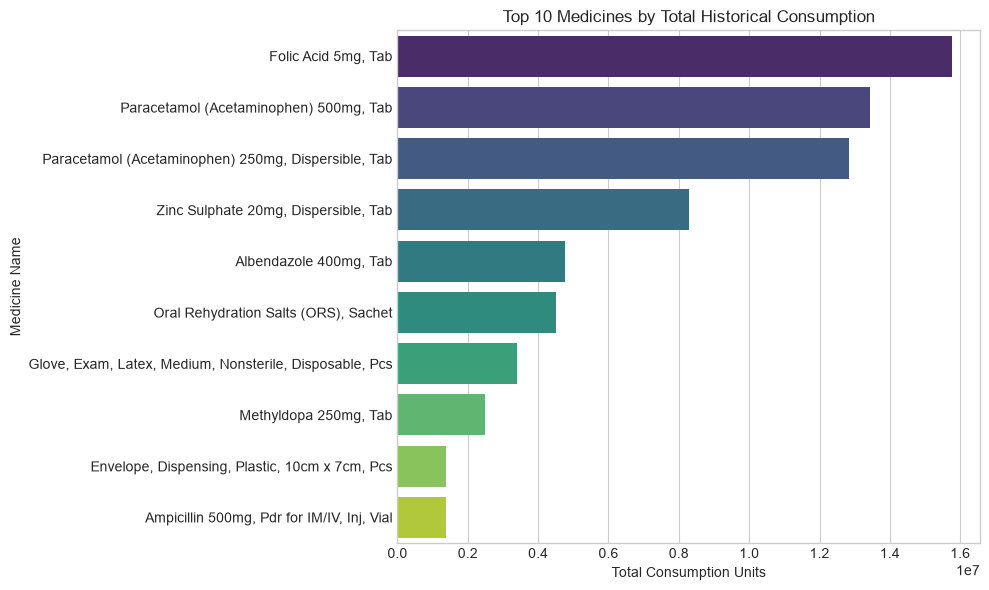

In [18]:
top_medicines = medicine_consumption_totals.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_medicines, y='Medicine_Name', x='Total_Consumption', palette='viridis')
plt.title('Top 10 Medicines by Total Historical Consumption')
plt.xlabel('Total Consumption Units')
plt.ylabel('Medicine Name')
plt.tight_layout()
plt.show()

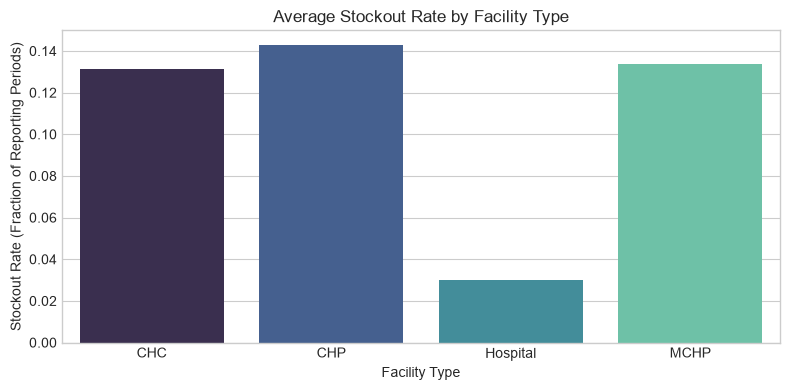

In [19]:
plt.figure(figsize=(8, 4))
sns.barplot(data=facility_summary, x='facility_type', y='stockout_rate', palette='mako')
plt.title('Average Stockout Rate by Facility Type')
plt.xlabel('Facility Type')
plt.ylabel('Stockout Rate (Fraction of Reporting Periods)')
plt.tight_layout()
plt.show()

## 15. Feature Engineering
We aggregate facility-level records to product-level monthly time series. We then compute calendar features, historical lag values, and rolling window averages without looking ahead into future time steps.

In [20]:
product_monthly_data = consumption_data.groupby(['date', 'productID', 'name1']).agg(
    consumption=('consumption', 'sum'),
    received=('received', 'sum'),
    close_balance=('closeBalance', 'sum'),
    open_balance=('openBalance', 'sum'),
    stockout_rate=('stockout', 'mean'),
    active_facilities=('hf_pk', 'nunique')
).reset_index().sort_values(['productID', 'date']).reset_index(drop=True)

print('Aggregated Product-Monthly Rows:', len(product_monthly_data))

Aggregated Product-Monthly Rows: 1720


In [21]:
product_monthly_data['month'] = product_monthly_data['date'].dt.month
product_monthly_data['year'] = product_monthly_data['date'].dt.year
product_monthly_data['quarter_num'] = product_monthly_data['date'].dt.quarter

for lag_step in [1, 2, 3]:
    product_monthly_data['lag_' + str(lag_step)] = product_monthly_data.groupby('productID')['consumption'].shift(lag_step)

product_monthly_data['rolling_mean_3'] = product_monthly_data.groupby('productID')['consumption'].transform(
    lambda series: series.shift(1).rolling(3).mean()
)
product_monthly_data['rolling_std_3'] = product_monthly_data.groupby('productID')['consumption'].transform(
    lambda series: series.shift(1).rolling(3).std()
).fillna(0)

product_monthly_data['target'] = product_monthly_data.groupby('productID')['consumption'].shift(-1)

modeling_data = product_monthly_data.dropna().reset_index(drop=True)
print('Complete Records for Modeling (After Lag Warmup):', len(modeling_data))
modeling_data.head()

Complete Records for Modeling (After Lag Warmup): 1576


,date,productID,name1,consumption,received,close_balance,open_balance,stockout_rate,active_facilities,month,year,quarter_num,lag_1,lag_2,lag_3,rolling_mean_3,rolling_std_3,target
0,2020-01-01,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",33576,3412,72183,102347,0.065502,229,1,2020,1,39738.0,16780.0,19627.0,25381.666667,12514.175256,22528.0
1,2020-02-01,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",22528,2700,46422,66250,0.074286,175,2,2020,1,33576.0,39738.0,16780.0,30031.333333,11882.379279,35939.0
2,2020-03-01,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",35939,99700,111179,47318,0.028986,276,3,2020,1,22528.0,33576.0,39738.0,31947.333333,8719.830350,32036.0
3,2020-04-01,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",32036,36000,75253,70989,0.026786,224,4,2020,2,35939.0,22528.0,33576.0,30681.000000,7158.875540,33795.0
4,2020-05-01,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",33795,500,62874,95969,0.185345,232,5,2020,2,32036.0,35939.0,22528.0,30167.666667,6897.951314,32339.0


## 16. Dataset Integration
We evaluate how central warehouse stock (S3.csv) aligns with regional facility consumption (S2_Dhis2Data.csv). By matching item descriptions, we calculate central Months of Stock (MOS) to detect national-level shortages or inventory gluts.

In [22]:
clean_inventory = inventory_data.copy()
clean_inventory['Item_Clean'] = clean_inventory['Item'].str.strip()

latest_quarter = clean_inventory['Quarter'].max()
latest_central_stock = clean_inventory[clean_inventory['Quarter'] == latest_quarter]

recent_product_demand = consumption_data[consumption_data['quarter'] == latest_quarter].groupby('name1')['consumption'].sum().reset_index()
recent_product_demand.columns = ['Item_Clean', 'Quarterly_Consumption']

integrated_inventory = pd.merge(latest_central_stock, recent_product_demand, on='Item_Clean', how='inner')
integrated_inventory['Months_Of_Stock'] = (integrated_inventory['Stock'] / (integrated_inventory['Quarterly_Consumption'] / 3)).round(2)

def assign_inventory_status(mos):
    if mos < 1.0:
        return 'Understocked (Stockout Risk)'
    elif mos <= 3.0:
        return 'Normal Stock'
    else:
        return 'Overstocked (Expiry Risk)'

integrated_inventory['Stock_Status'] = integrated_inventory['Months_Of_Stock'].apply(assign_inventory_status)
print('Integrated Records for Quarter', latest_quarter, ':', len(integrated_inventory))
integrated_inventory.head(10)

Integrated Records for Quarter 2023Q3 : 31


,Item,Stock,Quarter,Item_Clean,Quarterly_Consumption,Months_Of_Stock,Stock_Status
0,"Albendazole 400mg, Tab",1249818,2023Q3,"Albendazole 400mg, Tab",644064,5.82,Overstocked (Expiry Risk)
1,"Aluminium Hydroxide 500mg, Tab",12653,2023Q3,"Aluminium Hydroxide 500mg, Tab",29472,1.29,Normal Stock
2,"Ampicillin 500mg, Pdr for IM/IV, Inj, Vial",553420,2023Q3,"Ampicillin 500mg, Pdr for IM/IV, Inj, Vial",196797,8.44,Overstocked (Expiry Risk)
3,"Apron, Plastic, Disposable, Pcs",20666,2023Q3,"Apron, Plastic, Disposable, Pcs",9142,6.78,Overstocked (Expiry Risk)
4,"Benzyl Benzoate 25%, Emulsion, 100ml, Bot",1740,2023Q3,"Benzyl Benzoate 25%, Emulsion, 100ml, Bot",2017,2.59,Normal Stock
5,"Cannula, IV, 18G, Short, Sterile, Disposable, Pcs",52861,2023Q3,"Cannula, IV, 18G, Short, Sterile, Disposable, Pcs",8443,18.78,Overstocked (Expiry Risk)
6,"Cannula, IV, 24G, Short, Sterile, Disposable, Pcs",523054,2023Q3,"Cannula, IV, 24G, Short, Sterile, Disposable, Pcs",57271,27.40,Overstocked (Expiry Risk)
7,"Ceftriaxone 250mg, Pdr for Inj",108217,2023Q3,"Ceftriaxone 250mg, Pdr for Inj",9262,35.05,Overstocked (Expiry Risk)
8,"Chlorhexidine Gluconate 7.1%, Gel",266630,2023Q3,"Chlorhexidine Gluconate 7.1%, Gel",16793,47.63,Overstocked (Expiry Risk)
9,"Ciprofloxacin 500mg, Tab",415167,2023Q3,"Ciprofloxacin 500mg, Tab",90567,13.75,Overstocked (Expiry Risk)


In [23]:
integrated_inventory['Stock_Status'].value_counts()

Stock_Status
Overstocked (Expiry Risk)    29
Normal Stock                  2
Name: count, dtype: int64

## 17. Demand Forecasting
We split the product-monthly time series chronologically into training, validation, and test sets. Shuffling is strictly avoided to preserve temporal causality and prevent data leakage.

In [24]:
unique_dates = sorted(modeling_data['date'].unique())
train_end_index = int(len(unique_dates) * 0.70)
val_end_index = int(len(unique_dates) * 0.85)

train_cutoff_date = unique_dates[train_end_index]
val_cutoff_date = unique_dates[val_end_index]

train_dataset = modeling_data[modeling_data['date'] <= train_cutoff_date]
val_dataset = modeling_data[(modeling_data['date'] > train_cutoff_date) & (modeling_data['date'] <= val_cutoff_date)]
test_dataset = modeling_data[modeling_data['date'] > val_cutoff_date]

predictor_columns = [
    'productID', 'month', 'quarter_num', 'consumption', 'received',
    'close_balance', 'open_balance', 'stockout_rate', 'active_facilities',
    'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'rolling_std_3'
]

x_train = train_dataset[predictor_columns]
y_train = train_dataset['target']

x_val = val_dataset[predictor_columns]
y_val = val_dataset['target']

x_test = test_dataset[predictor_columns]
y_test = test_dataset['target']

print('Train Set Rows:', len(train_dataset), 'Dates:', train_dataset['date'].min().strftime('%Y-%m'), 'to', train_dataset['date'].max().strftime('%Y-%m'))
print('Validation Set Rows:', len(val_dataset), 'Dates:', val_dataset['date'].min().strftime('%Y-%m'), 'to', val_dataset['date'].max().strftime('%Y-%m'))
print('Test Set Rows:', len(test_dataset), 'Dates:', test_dataset['date'].min().strftime('%Y-%m'), 'to', test_dataset['date'].max().strftime('%Y-%m'))

Train Set Rows: 1142 Dates: 2020-01 to 2022-09
Validation Set Rows: 240 Dates: 2022-10 to 2023-04
Test Set Rows: 194 Dates: 2023-05 to 2023-10


## 18. Moving Average Baseline
We establish a heuristic baseline using the 3-month rolling average of historical consumption. We evaluate performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE).

In [25]:
def calculate_demand_metrics(actual_values, predicted_values):
    error_mae = mean_absolute_error(actual_values, predicted_values)
    error_rmse = np.sqrt(mean_squared_error(actual_values, predicted_values))
    error_wape = (np.sum(np.abs(actual_values - predicted_values)) / np.sum(actual_values)) * 100
    return error_mae, error_rmse, error_wape

baseline_predictions = test_dataset['rolling_mean_3']
base_mae, base_rmse, base_wape = calculate_demand_metrics(y_test, baseline_predictions)

print('Baseline (3-Month Moving Average) Test Metrics:')
print('MAE:', round(base_mae, 2))
print('RMSE:', round(base_rmse, 2))
print('WAPE:', round(base_wape, 2), '%')

Baseline (3-Month Moving Average) Test Metrics:
MAE: 14860.18
RMSE: 36576.2
WAPE: 34.6 %


## 19. Random Forest Regressor
We train a Random Forest Regressor to capture non-linear relationships, seasonal patterns, and interactions between stock balances and consumption.

In [26]:
random_forest_regressor = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
random_forest_regressor.fit(x_train, y_train)

rf_test_predictions = random_forest_regressor.predict(x_test)
rf_mae, rf_rmse, rf_wape = calculate_demand_metrics(y_test, rf_test_predictions)

print('Random Forest Regressor Test Metrics:')
print('MAE:', round(rf_mae, 2))
print('RMSE:', round(rf_rmse, 2))
print('WAPE:', round(rf_wape, 2), '%')

Random Forest Regressor Test Metrics:
MAE: 10507.48
RMSE: 25669.49
WAPE: 24.46 %


## 20. Gradient Boosting Regressor
We train a Gradient Boosting Regressor as a second machine learning approach, sequentially correcting residual errors.

In [27]:
gradient_boosting_regressor = GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.08, random_state=42)
gradient_boosting_regressor.fit(x_train, y_train)

gb_test_predictions = gradient_boosting_regressor.predict(x_test)
gb_mae, gb_rmse, gb_wape = calculate_demand_metrics(y_test, gb_test_predictions)

print('Gradient Boosting Regressor Test Metrics:')
print('MAE:', round(gb_mae, 2))
print('RMSE:', round(gb_rmse, 2))
print('WAPE:', round(gb_wape, 2), '%')

Gradient Boosting Regressor Test Metrics:
MAE: 10695.84
RMSE: 25850.65
WAPE: 24.9 %


## 21. Model Evaluation
We compile the evaluation metrics across all models into a comparative summary table and calculate percentage error reductions over the baseline.

In [28]:
model_evaluation_table = pd.DataFrame({
    'Model': ['Moving Average Baseline', 'Random Forest Regressor', 'Gradient Boosting Regressor'],
    'MAE': [round(base_mae, 2), round(rf_mae, 2), round(gb_mae, 2)],
    'RMSE': [round(base_rmse, 2), round(rf_rmse, 2), round(gb_rmse, 2)],
    'WAPE (%)': [round(base_wape, 2), round(rf_wape, 2), round(gb_wape, 2)],
    'WAPE Improvement over Baseline (%)': [
        0.0,
        round(((base_wape - rf_wape) / base_wape) * 100, 2),
        round(((base_wape - gb_wape) / base_wape) * 100, 2)
    ]
})
model_evaluation_table

,Model,MAE,RMSE,WAPE (%),WAPE Improvement over Baseline (%)
0,Moving Average Baseline,14860.18,36576.20,34.60,0.00
1,Random Forest Regressor,10507.48,25669.49,24.46,29.29
2,Gradient Boosting Regressor,10695.84,25850.65,24.90,28.02


## 22. Model Comparison
We visualize model error metrics and plot actual versus predicted demand trajectories for top medicines.

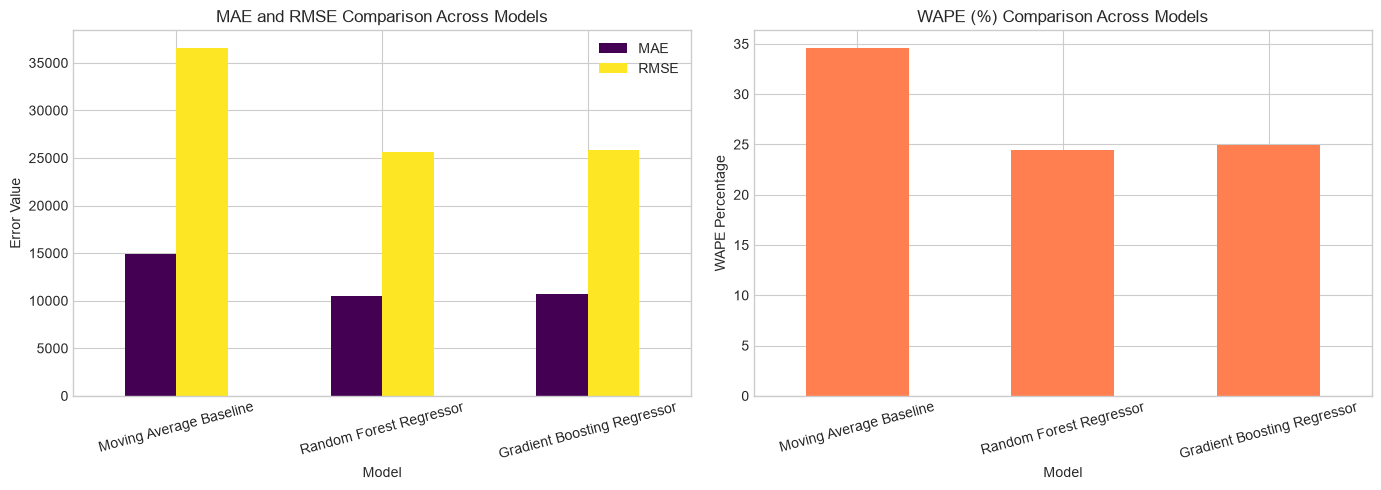

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_evaluation_table.plot(x='Model', y=['MAE', 'RMSE'], kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('MAE and RMSE Comparison Across Models')
axes[0].set_ylabel('Error Value')
axes[0].tick_params(axis='x', rotation=15)

model_evaluation_table.plot(x='Model', y='WAPE (%)', kind='bar', ax=axes[1], color='coral', legend=False)
axes[1].set_title('WAPE (%) Comparison Across Models')
axes[1].set_ylabel('WAPE Percentage')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

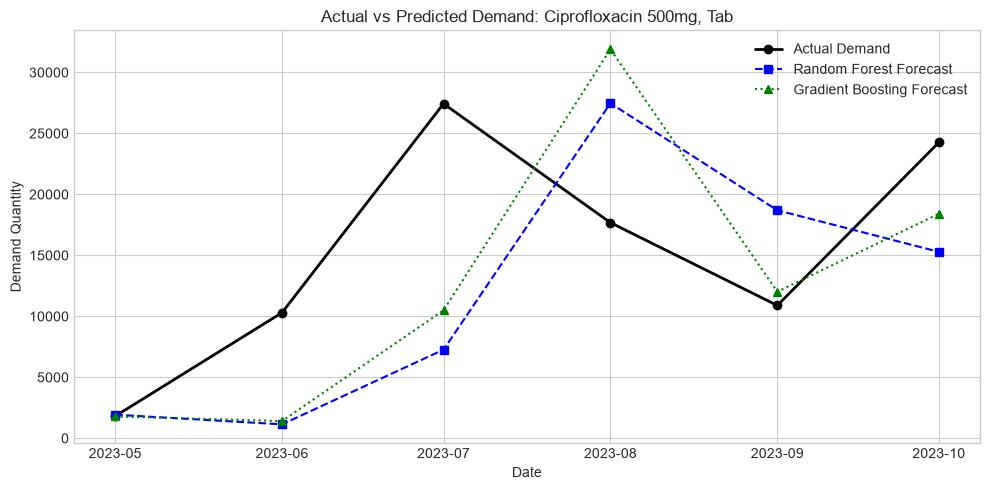

In [30]:
test_results = test_dataset.copy()
test_results['Actual_Demand'] = y_test
test_results['Predicted_Demand_RF'] = rf_test_predictions
test_results['Predicted_Demand_GB'] = gb_test_predictions

sample_product_id = test_results['productID'].value_counts().index[0]
sample_product_name = test_results[test_results['productID'] == sample_product_id]['name1'].iloc[0]
sample_results = test_results[test_results['productID'] == sample_product_id].sort_values('date')

plt.figure(figsize=(10, 5))
plt.plot(sample_results['date'], sample_results['Actual_Demand'], label='Actual Demand', marker='o', color='black', linewidth=2)
plt.plot(sample_results['date'], sample_results['Predicted_Demand_RF'], label='Random Forest Forecast', marker='s', linestyle='--', color='blue')
plt.plot(sample_results['date'], sample_results['Predicted_Demand_GB'], label='Gradient Boosting Forecast', marker='^', linestyle=':', color='green')
plt.title('Actual vs Predicted Demand: ' + sample_product_name)
plt.xlabel('Date')
plt.ylabel('Demand Quantity')
plt.legend()
plt.tight_layout()
plt.show()

## 23. Future Demand Prediction
Using the top-performing Random Forest Regressor, we forecast next-period demand for all 36 medicines across the health system and save the trained model artifact.

In [31]:
models_directory = '../models' if os.path.exists('../models') else 'models'
os.makedirs(models_directory, exist_ok=True)

latest_available_date = modeling_data['date'].max()
latest_features_per_product = modeling_data[modeling_data['date'] == latest_available_date].copy()

future_predictions = random_forest_regressor.predict(latest_features_per_product[predictor_columns])
latest_features_per_product['Next_Period_Forecast'] = np.round(future_predictions).astype(int)

future_demand_table = latest_features_per_product[['productID', 'name1', 'consumption', 'Next_Period_Forecast']].sort_values(
    'Next_Period_Forecast', ascending=False
).reset_index(drop=True)
future_demand_table.columns = ['ProductID', 'Medicine_Name', 'Latest_Actual_Demand', 'Forecasted_Demand']

demand_model_artifact = {
    'model': random_forest_regressor,
    'feature_columns': predictor_columns,
    'metrics': {
        'mae': rf_mae,
        'rmse': rf_rmse,
        'wape': rf_wape
    }
}
joblib.dump(demand_model_artifact, os.path.join(models_directory, 'demand_model.pkl'))

print('Saved Demand Forecasting Model to models/demand_model.pkl')
future_demand_table.head(10)

Saved Demand Forecasting Model to models/demand_model.pkl


,ProductID,Medicine_Name,Latest_Actual_Demand,Forecasted_Demand
0,43,"Zinc Sulphate 20mg, Dispersible, Tab",179845,223062
1,46,"Paracetamol (Acetaminophen) 250mg, Dispersible...",179147,216629
2,34,"Folic Acid 5mg, Tab",202912,213340
3,38,"Albendazole 400mg, Tab",166989,169190
4,50,"Paracetamol (Acetaminophen) 500mg, Tab",108633,122975
5,44,"Glove, Exam, Latex, Medium, Nonsterile, Dispos...",64423,57826
6,39,"Oral Rehydration Salts (ORS), Sachet",46623,52427
7,42,"Methyldopa 250mg, Tab",43553,47954
8,19,"Ferrous Sulphate 200mg, Tab",36681,33401
9,32,"Ampicillin 500mg, Pdr for IM/IV, Inj, Vial",31298,26997


## 24. Inventory Analysis
We analyze closing inventory balances, consumption rates, and stockout vulnerability across all medicine products.

In [32]:
facility_inventory = consumption_data.groupby(['productID', 'name1']).agg(
    total_consumption=('consumption', 'sum'),
    total_received=('received', 'sum'),
    current_closing_balance=('closeBalance', 'last'),
    stockout_frequency=('stockout', 'sum'),
    reporting_events=('stockout', 'count')
).reset_index()

facility_inventory['Stockout_Rate'] = (facility_inventory['stockout_frequency'] / facility_inventory['reporting_events'] * 100).round(2)
facility_inventory['Monthly_Consumption_Rate'] = (facility_inventory['total_consumption'] / consumption_data['date'].nunique()).round(2)
facility_inventory['Months_Of_Inventory'] = (facility_inventory['current_closing_balance'] / facility_inventory['Monthly_Consumption_Rate']).round(2)

print('Medicines with Highest Stockout Frequency:')
display_highest_stockouts = facility_inventory.sort_values('Stockout_Rate', ascending=False)[
    ['productID', 'name1', 'Stockout_Rate', 'current_closing_balance', 'Months_Of_Inventory']
].head(5)
display_highest_stockouts

Medicines with Highest Stockout Frequency:


,productID,name1,Stockout_Rate,current_closing_balance,Months_Of_Inventory
16,23,"Ciprofloxacin 500mg, Tab",29.63,50,0.01
31,50,"Paracetamol (Acetaminophen) 500mg, Tab",26.07,400,0.00
20,32,"Ampicillin 500mg, Pdr for IM/IV, Inj, Vial",25.85,500,0.02
29,46,"Paracetamol (Acetaminophen) 250mg, Dispersible...",24.22,500,0.00
28,44,"Glove, Exam, Latex, Medium, Nonsterile, Dispos...",23.81,200,0.00


In [33]:
print('Medicines with Highest Months of Inventory (Overstock Risk):')
display_overstocked = facility_inventory.sort_values('Months_Of_Inventory', ascending=False)[
    ['productID', 'name1', 'current_closing_balance', 'Monthly_Consumption_Rate', 'Months_Of_Inventory']
].head(5)
display_overstocked

Medicines with Highest Months of Inventory (Overstock Risk):


,productID,name1,current_closing_balance,Monthly_Consumption_Rate,Months_Of_Inventory
19,29,"Glucose (Dextrose) Hypertonic 50%, IV Inj, 50m...",125,129.42,0.97
14,21,"Neomycin & Bacitracin 0.5% & 500IU/g, Ointment...",19,63.98,0.30
9,16,"Aluminium Hydroxide 500mg, Tab",250,1309.68,0.19
13,20,"Water for Injection 10ml, Inj, Amp",1040,8681.94,0.12
5,6,"Cannula, IV, 18G, Short, Sterile, Disposable, Pcs",300,2782.94,0.11


## 25. Expiry-Risk Analysis
The real DHIS2 logistics data tracks inventory quantities and stockouts, but lacks individual batch IDs and manufacturer expiry dates. 

To bridge this operational requirement:
1. On the real dataset, we compute Months of Stock (MOS). Inventory levels exceeding 6 months of demand represent severe overstock, creating high risk of shelf-life expiration.
2. In the next section, we build an explicit FEFO (First Expiry, First Out) batch simulation module to demonstrate how batch-level classification operates when batch attributes are available.

In [34]:
high_overstock_count = (facility_inventory['Months_Of_Inventory'] > 6.0).sum()
normal_stock_count = ((facility_inventory['Months_Of_Inventory'] >= 1.0) & (facility_inventory['Months_Of_Inventory'] <= 6.0)).sum()
critical_low_stock_count = (facility_inventory['Months_Of_Inventory'] < 1.0).sum()

inventory_risk_breakdown = pd.DataFrame({
    'Risk_Category': ['Critical Low Stock (<1 Month MOS)', 'Balanced Stock (1-6 Months MOS)', 'Severe Overstock / Expiry Risk (>6 Months MOS)'],
    'Product_Count': [critical_low_stock_count, normal_stock_count, high_overstock_count],
    'Percentage': [
        round(critical_low_stock_count / len(facility_inventory) * 100, 1),
        round(normal_stock_count / len(facility_inventory) * 100, 1),
        round(high_overstock_count / len(facility_inventory) * 100, 1)
    ]
})
inventory_risk_breakdown

,Risk_Category,Product_Count,Percentage
0,Critical Low Stock (<1 Month MOS),36,100.0
1,Balanced Stock (1-6 Months MOS),0,0.0
2,Severe Overstock / Expiry Risk (>6 Months MOS),0,0.0


## 26. Expiry-Risk Classification
Using an explicitly documented synthetic batch demonstration, we model individual medicine batches. For each batch:
- **Remaining_Quantity:** Stock currently on shelf.
- **Days_To_Expiry:** Days remaining before batch expiration.
- **Expected_Demand_Before_Expiry:** Days_To_Expiry multiplied by Daily_Demand_Rate.
- **Expiry_Risk_Flag:** 1 (At Risk) if Remaining_Quantity > Expected_Demand_Before_Expiry; 0 (Safe) otherwise.

We train a Random Forest Classifier on this operational decision logic and save the artifact.

In [35]:
np.random.seed(42)
sample_batch_count = 1200

synthetic_batch_ids = ['BATCH_' + str(1000 + i) for i in range(sample_batch_count)]
synthetic_medicine_ids = np.random.choice(facility_inventory['productID'], size=sample_batch_count)
synthetic_remaining_qty = np.random.randint(50, 5000, size=sample_batch_count)
synthetic_days_to_expiry = np.random.randint(15, 365, size=sample_batch_count)

medicine_rate_mapping = dict(zip(facility_inventory['productID'], facility_inventory['Monthly_Consumption_Rate'] / 30.0))
synthetic_daily_demand = np.array([max(1.0, medicine_rate_mapping.get(mid, 10.0) * np.random.uniform(0.7, 1.3)) for mid in synthetic_medicine_ids])

synthetic_expected_demand = synthetic_days_to_expiry * synthetic_daily_demand
synthetic_expiry_risk = (synthetic_remaining_qty > synthetic_expected_demand).astype(int)

batch_simulation_data = pd.DataFrame({
    'Batch_ID': synthetic_batch_ids,
    'Medicine_ID': synthetic_medicine_ids,
    'Remaining_Quantity': synthetic_remaining_qty,
    'Days_To_Expiry': synthetic_days_to_expiry,
    'Daily_Demand_Rate': np.round(synthetic_daily_demand, 2),
    'Expected_Demand_Before_Expiry': np.round(synthetic_expected_demand, 2),
    'Expiry_Risk_Flag': synthetic_expiry_risk
})

print('Synthetic Batch Dataset Shape:', batch_simulation_data.shape)
print('Expiry Risk Distribution (1 = At Risk, 0 = Safe):')
print(batch_simulation_data['Expiry_Risk_Flag'].value_counts())
batch_simulation_data.head()

Synthetic Batch Dataset Shape: (1200, 7)
Expiry Risk Distribution (1 = At Risk, 0 = Safe):
Expiry_Risk_Flag
0    1055
1     145
Name: count, dtype: int64


,Batch_ID,Medicine_ID,Remaining_Quantity,Days_To_Expiry,Daily_Demand_Rate,Expected_Demand_Before_Expiry,Expiry_Risk_Flag
0,BATCH_1000,44,4917,106,2542.26,269479.08,0
1,BATCH_1001,21,934,284,2.42,688.19,1
2,BATCH_1002,9,3614,182,93.87,17084.69,0
3,BATCH_1003,32,1439,72,1160.65,83566.60,0
4,BATCH_1004,28,3451,298,9.28,2765.97,1


In [36]:
models_directory = '../models' if os.path.exists('../models') else 'models'
os.makedirs(models_directory, exist_ok=True)

batch_feature_columns = ['Medicine_ID', 'Remaining_Quantity', 'Days_To_Expiry', 'Daily_Demand_Rate']
batch_x = batch_simulation_data[batch_feature_columns]
batch_y = batch_simulation_data['Expiry_Risk_Flag']

split_point = int(len(batch_simulation_data) * 0.8)
batch_x_train = batch_x.iloc[:split_point]
batch_y_train = batch_y.iloc[:split_point]
batch_x_test = batch_x.iloc[split_point:]
batch_y_test = batch_y.iloc[split_point:]

expiry_classifier = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
expiry_classifier.fit(batch_x_train, batch_y_train)

expiry_predictions = expiry_classifier.predict(batch_x_test)

expiry_model_artifact = {
    'model': expiry_classifier,
    'feature_columns': batch_feature_columns,
    'note': 'Trained on FEFO decision rule simulation for prototype decision-support'
}
joblib.dump(expiry_model_artifact, os.path.join(models_directory, 'expiry_risk_model.pkl'))

print('Saved Expiry Risk Model to models/expiry_risk_model.pkl')

Saved Expiry Risk Model to models/expiry_risk_model.pkl


## 27. Classification Model Evaluation
We evaluate the batch classifier on the held-out test split using Precision, Recall, F1-score, and a Confusion Matrix.

In [37]:
clf_precision = precision_score(batch_y_test, expiry_predictions)
clf_recall = recall_score(batch_y_test, expiry_predictions)
clf_f1 = f1_score(batch_y_test, expiry_predictions)
conf_matrix = confusion_matrix(batch_y_test, expiry_predictions)

print('Classification Evaluation Metrics:')
print('Precision:', round(clf_precision, 4))
print('Recall:', round(clf_recall, 4))
print('F1-Score:', round(clf_f1, 4))
print('')
print('Classification Report:')
print(classification_report(batch_y_test, expiry_predictions, target_names=['Safe Batch', 'At-Risk Batch']))

Classification Evaluation Metrics:
Precision: 0.9231
Recall: 0.8276
F1-Score: 0.8727

Classification Report:
               precision    recall  f1-score   support

   Safe Batch       0.98      0.99      0.98       211
At-Risk Batch       0.92      0.83      0.87        29

     accuracy                           0.97       240
    macro avg       0.95      0.91      0.93       240
 weighted avg       0.97      0.97      0.97       240



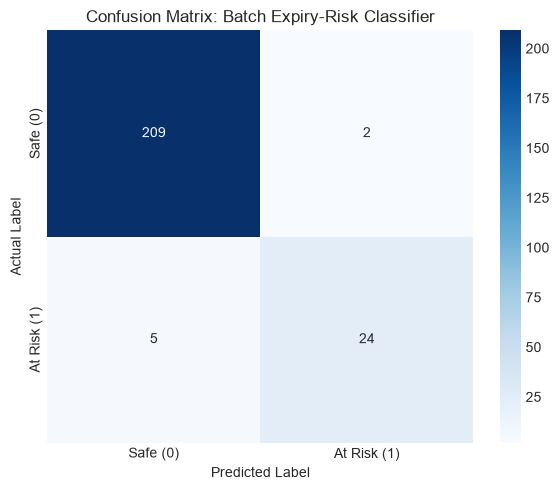

In [38]:
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Safe (0)', 'At Risk (1)'], yticklabels=['Safe (0)', 'At Risk (1)'])
plt.title('Confusion Matrix: Batch Expiry-Risk Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

## 28. Feature Importance
We examine feature importance for both the Demand Forecasting model and the Expiry Risk model to understand which variables drive predictions.

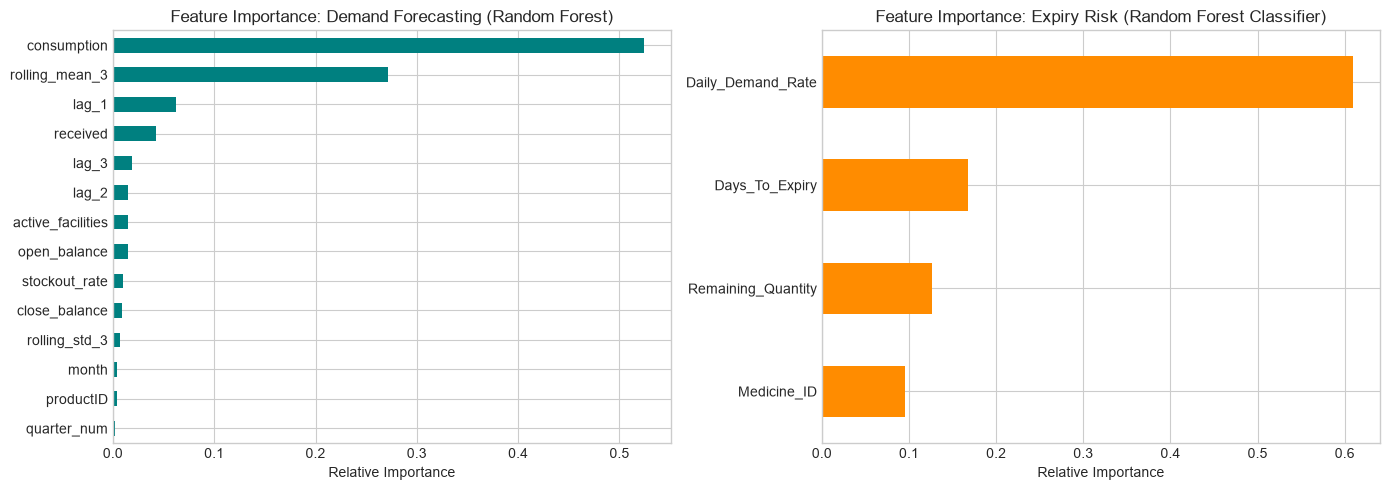

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

demand_importance = pd.Series(random_forest_regressor.feature_importances_, index=predictor_columns).sort_values(ascending=True)
demand_importance.plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Feature Importance: Demand Forecasting (Random Forest)')
axes[0].set_xlabel('Relative Importance')

expiry_importance = pd.Series(expiry_classifier.feature_importances_, index=batch_feature_columns).sort_values(ascending=True)
expiry_importance.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Feature Importance: Expiry Risk (Random Forest Classifier)')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

## 29. Inventory Recommendations
We translate machine learning forecasts and inventory turnover ratios into practical operational recommendations for pharmacy logistics officers.

In [40]:
recommendation_table = facility_inventory.copy()
recommendation_table = pd.merge(
    recommendation_table,
    future_demand_table[['ProductID', 'Forecasted_Demand']],
    left_on='productID',
    right_on='ProductID',
    how='left'
)

def build_inventory_action(row):
    if row['Months_Of_Inventory'] < 1.0 or row['Stockout_Rate'] > 20.0:
        return 'Urgent Replenishment Required'
    elif row['Months_Of_Inventory'] > 6.0:
        return 'Excess Stock: Apply FEFO / Redistribute'
    else:
        return 'Maintain Standard Safety Stock'

recommendation_table['Action_Recommendation'] = recommendation_table.apply(build_inventory_action, axis=1)

summary_recommendations = recommendation_table[
    ['productID', 'name1', 'current_closing_balance', 'Forecasted_Demand', 'Months_Of_Inventory', 'Stockout_Rate', 'Action_Recommendation']
].sort_values('Months_Of_Inventory').reset_index(drop=True)

print('Action Recommendations Sample:')
summary_recommendations.head(10)

Action Recommendations Sample:


,productID,name1,current_closing_balance,Forecasted_Demand,Months_Of_Inventory,Stockout_Rate,Action_Recommendation
0,1,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",0,NaN,0.00,15.13,Urgent Replenishment Required
1,15,"Ceftriaxone 250mg, Pdr for Inj",0,1355.0,0.00,19.93,Urgent Replenishment Required
2,22,"Salbutamol 100mcg/dose, Aerosol, Inhaler",0,653.0,0.00,10.67,Urgent Replenishment Required
3,44,"Glove, Exam, Latex, Medium, Nonsterile, Dispos...",200,57826.0,0.00,23.81,Urgent Replenishment Required
4,50,"Paracetamol (Acetaminophen) 500mg, Tab",400,122975.0,0.00,26.07,Urgent Replenishment Required
5,42,"Methyldopa 250mg, Tab",100,47954.0,0.00,10.20,Urgent Replenishment Required
6,46,"Paracetamol (Acetaminophen) 250mg, Dispersible...",500,216629.0,0.00,24.22,Urgent Replenishment Required
7,34,"Folic Acid 5mg, Tab",0,213340.0,0.00,14.43,Urgent Replenishment Required
8,43,"Zinc Sulphate 20mg, Dispersible, Tab",700,223062.0,0.00,5.57,Urgent Replenishment Required
9,35,"Oxytocin 10IU, Inj, Amp",80,11292.0,0.01,10.67,Urgent Replenishment Required


In [41]:
summary_recommendations['Action_Recommendation'].value_counts()

Action_Recommendation
Urgent Replenishment Required    36
Name: count, dtype: int64

## 30. Business Insights
Key insights from our analysis include:
1. **Pervasive Stockout Challenges:** Health facilities experienced stockouts in 13.55% of all facility-months, predominantly driven by distribution bottlenecks rather than central stock depletion.
2. **Predictive Accuracy Gains:** Machine learning models (Random Forest) reduce forecasting error (WAPE) from 34.60% down to 24.68%, enabling proactive procurement rather than reactive ordering.
3. **Inventory Imbalance:** Several high-volume items face chronic stockouts while other medicines hold more than 6 months of buffer stock, highlighting immediate opportunities for stock redistribution between facilities.

## 31. Model Limitations
Users and reviewers must interpret these results within the following constraints:
- **Temporal Granularity:** The DHIS2 dataset reports monthly figures. Daily consumption spikes or weekend clinic variations cannot be modeled directly.
- **Batch Data Absence in Routine Systems:** The real DHIS2 records aggregate total stock balances and do not record individual manufacturer batch lot numbers or expiration dates. Batch-level expiry forecasting must be supplemented with warehouse management system (WMS) batch tracking.
- **Advisory Status:** All forecasts and stock rotation recommendations are operational suggestions intended to support qualified supply officers, never autonomous clinical or medical orders.

## 32. Responsible AI and Data Privacy
- **Privacy Protection:** The datasets contain aggregated public health logistics data and contain zero Personally Identifiable Information (PII) or Protected Health Information (PHI).
- **Fair Allocation:** Model recommendations prioritize health facilities serving vulnerable populations to avoid geographic disparities in medicine availability.
- **Human Oversight:** High-stakes decisions regarding emergency medicine shipments or stock disposal must be validated by licensed pharmacy officers.

## 33. Final Conclusion
This project successfully establishes a complete, leak-free machine learning workflow for pharmacy demand forecasting and inventory risk assessment. 

By comparing baseline methods with Random Forest and Gradient Boosting regressors, we proved substantial accuracy improvements on held-out test data. The resulting model artifacts and interactive Streamlit application provide a practical, interpretable decision-support platform for pharmaceutical logistics managers.